In [2]:

import sys
from pathlib import Path

print("Python version:", sys.version.split()[0])
print("Jupyter is working!")
print("Current folder:", Path.cwd())


Python version: 3.13.9
Jupyter is working!
Current folder: C:\Users\DELL


In [3]:

from pathlib import Path

raw_folder = Path(
    r"C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar\data\raw"
)

print("Folder exists:", raw_folder.exists())
print("\nFiles available:")

for file in raw_folder.iterdir():
    print(file.name)


Folder exists: True

Files available:
CMO-Historical-Data-Monthly.xlsx
world_bank_commodity_prices.xlsx


In [4]:

import pandas as pd

file_path = raw_folder / "world_bank_commodity_prices.xlsx"

print("File exists:", file_path.exists())

excel_file = pd.ExcelFile(file_path)

print("\nAvailable worksheets:")
print(excel_file.sheet_names)


File exists: True

Available worksheets:
['Mismatch Details', 'Monthly Prices', 'Monthly Indices', 'Description', 'Index Weights']


In [5]:

# Reload the Monthly Prices sheet with no header assumed
df = pd.read_excel(
    file_path,
    sheet_name="Monthly Prices",
    header=None
)

# Display the first 10 rows with their row numbers
display(df.head(10))


,0,1,2,3,4,5,6,7,8,9,...,62,63,64,65,66,67,68,69,70,71
0,World Bank Commodity Price Data (The Pink Sheet),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"monthly prices in nominal US dollars, 1960 to ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,(monthly series are available only in nominal ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Updated on October 02, 2026",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI","Coal, Australian","Coal, South African **","Natural gas, US","Natural gas, Europe","Liquefied natural gas, Japan",...,Aluminum,"Iron ore, cfr spot",Copper,Lead,Tin,Nickel,Zinc,Gold,Platinum,Silver
5,NaN,($/bbl),($/bbl),($/bbl),($/bbl),($/mt),($/mt),($/mmbtu),($/mmbtu),($/mmbtu),...,($/mt),($/dmtu),($/mt),($/mt),($/mt),($/mt),($/mt),($/troy oz),($/troy oz),($/troy oz)
6,1960M01,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,715,206,2180,1631,261,35,84,0.9
7,1960M02,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,728,204,2180,1631,245,35,84,0.9
8,1960M03,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,685,210,2174,1631,249,35,84,0.9
9,1960M04,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,723,214,2178,1631,255,35,84,0.9


In [6]:

# Get the commodity names from row 4
column_names = df.iloc[4].tolist()

# Name the first column Month
column_names[0] = "Month"

# Keep monthly data from row 6 onward
df = df.iloc[6:].copy()

# Apply the correct column names
df.columns = column_names

# Reset the row numbers
df = df.reset_index(drop=True)

# Display the cleaned structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (801, 72)

Column names:
['Month', 'Crude oil, average', 'Crude oil, Brent', 'Crude oil, Dubai', 'Crude oil, WTI', 'Coal, Australian', 'Coal, South African **', 'Natural gas, US', 'Natural gas, Europe', 'Liquefied natural gas, Japan', 'Natural gas index', 'Cocoa', 'Coffee, Arabica', 'Coffee, Robusta', 'Tea, avg 3 auctions', 'Tea, Colombo', 'Tea, Kolkata', 'Tea, Mombasa', 'Coconut oil', 'Groundnuts', 'Fish meal', 'Groundnut oil **', 'Palm oil', 'Palm kernel oil', 'Soybeans', 'Soybean oil', 'Soybean meal', 'Rapeseed oil', 'Sunflower oil', 'Barley', 'Maize', 'Sorghum', 'Rice, Thai 5% ', 'Rice, Thai 25% ', 'Rice, Thai A.1', 'Rice, Viet Namese 5%', 'Wheat, US SRW', 'Wheat, US HRW', 'Banana, Europe', 'Banana, US', 'Orange', 'Beef **', 'Chicken **', 'Lamb **', 'Shrimps, Mexican', 'Sugar, EU', 'Sugar, US', 'Sugar, world', 'Tobacco, US import u.v.', 'Logs, Cameroon', 'Logs, Malaysian', 'Sawnwood, Cameroon', 'Sawnwood, Malaysian', 'Plywood', 'Cotton, A Index', 'Rubber, TSR20 **', 

,Month,"Crude oil, average","Crude oil, Brent","Crude oil, Dubai","Crude oil, WTI","Coal, Australian","Coal, South African **","Natural gas, US","Natural gas, Europe","Liquefied natural gas, Japan",...,Aluminum,"Iron ore, cfr spot",Copper,Lead,Tin,Nickel,Zinc,Gold,Platinum,Silver
0,1960M01,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,715,206,2180,1631,261,35,84,0.9
1,1960M02,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,728,204,2180,1631,245,35,84,0.9
2,1960M03,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,685,210,2174,1631,249,35,84,0.9
3,1960M04,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,723,214,2178,1631,255,35,84,0.9
4,1960M05,1.6,1.6,1.6,…,…,…,0.14,0.4,…,...,511,11.4,685,213,2163,1631,254,35,84,0.9


In [7]:

print("First column:", df.columns[0])
print("\nFirst five months:")
print(df["Month"].head().tolist())

print("\nAvailable food and fuel columns:")
for col in df.columns:
    if any(word in str(col).lower() for word in [
        "wheat", "rice", "maize", "oil", "urea", "fertilizer", "fertiliser"
    ]):
        print(col)


First column: Month

First five months:
['1960M01', '1960M02', '1960M03', '1960M04', '1960M05']

Available food and fuel columns:
Crude oil, average
Crude oil, Brent
Crude oil, Dubai
Crude oil, WTI
Coconut oil
Groundnut oil **
Palm oil
Palm kernel oil
Soybean oil
Rapeseed oil
Sunflower oil
Maize
Rice, Thai 5% 
Rice, Thai 25% 
Rice, Thai A.1
Rice, Viet Namese 5%
Wheat, US SRW
Wheat, US HRW
Urea 


In [8]:

# Convert month labels into proper dates
df["Month"] = pd.to_datetime(
    df["Month"],
    format="%YM%m",
    errors="coerce"
)

# Check the result
print("First five dates:")
print(df["Month"].head())

print("\nLatest date:")
print(df["Month"].max())

print("\nMissing dates:", df["Month"].isna().sum())


First five dates:
0   1960-01-01
1   1960-02-01
2   1960-03-01
3   1960-04-01
4   1960-05-01
Name: Month, dtype: datetime64[ns]

Latest date:
2026-09-01 00:00:00

Missing dates: 0


In [9]:
import numpy as np
# Convert unavailable-value markers into missing values
df = df.replace(["...", "…", "..", ""], np.nan)

# Convert all commodity columns to numbers
for col in df.columns:
    if col != "Month":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Check the results
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes.head(10))

print("\nMissing values in key indicators:")
key_columns = [
    "Crude oil, Brent",
    "Maize",
    "Rice, Thai 5%",
    "Wheat, US HRW",
    "Urea"
]

display(df[key_columns].isna().sum())


C:\Users\DELL\AppData\Local\Temp\ipykernel_29732\96442215.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(["...", "…", "..", ""], np.nan)


Dataset shape: (801, 72)

Data types:
Month                           datetime64[ns]
Crude oil, average                     float64
Crude oil, Brent                       float64
Crude oil, Dubai                       float64
Crude oil, WTI                         float64
Coal, Australian                       float64
Coal, South African **                 float64
Natural gas, US                        float64
Natural gas, Europe                    float64
Liquefied natural gas, Japan           float64
dtype: object

Missing values in key indicators:


KeyError: "['Rice, Thai 5%', 'Urea'] not in index"

In [10]:

print("Available columns related to food, fuel and fertiliser:\n")

for col in df.columns:
    name = str(col).lower()

    if any(word in name for word in [
        "crude oil", "maize", "rice", "wheat",
        "urea", "fertilizer", "fertiliser"
    ]):
        print(repr(col))


Available columns related to food, fuel and fertiliser:

'Crude oil, average'
'Crude oil, Brent'
'Crude oil, Dubai'
'Crude oil, WTI'
'Maize'
'Rice, Thai 5% '
'Rice, Thai 25% '
'Rice, Thai A.1'
'Rice, Viet Namese 5%'
'Wheat, US SRW'
'Wheat, US HRW'
'Urea '


In [11]:

key_columns = [
    col for col in df.columns
    if any(word in str(col).lower() for word in [
        "crude oil, brent", "maize", "rice", "wheat", "urea"
    ])
]

missing_summary = pd.DataFrame({
    "Missing values": df[key_columns].isna().sum(),
    "Missing percentage": (df[key_columns].isna().mean() * 100).round(2)
})

display(missing_summary)


,Missing values,Missing percentage
"Crude oil, Brent",0,0.00
Maize,0,0.00
"Rice, Thai 5%",0,0.00
"Rice, Thai 25%",316,39.45
"Rice, Thai A.1",312,38.95
"Rice, Viet Namese 5%",538,67.17
"Wheat, US SRW",228,28.46
"Wheat, US HRW",0,0.00
Urea,0,0.00


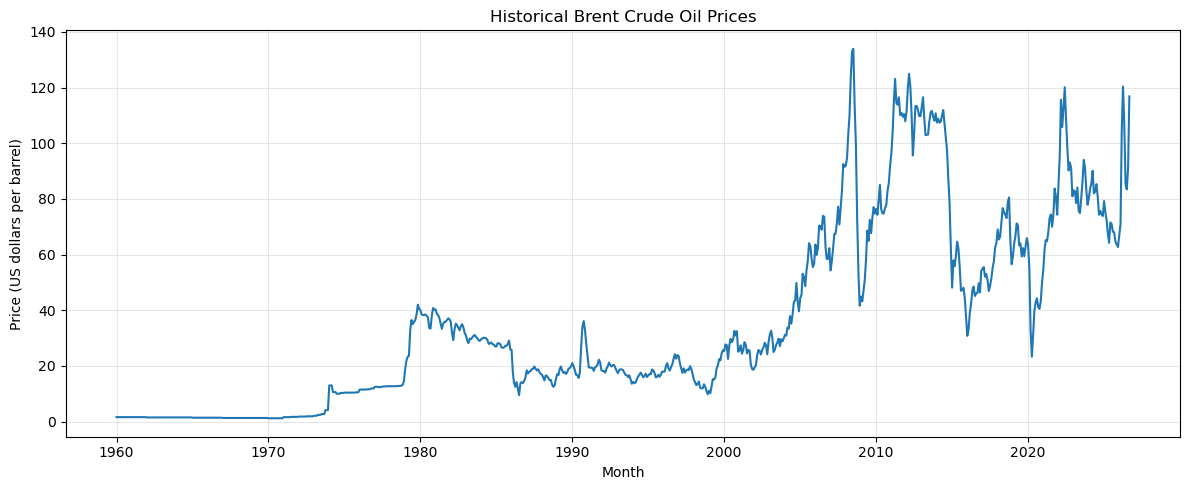

In [12]:

import matplotlib.pyplot as plt

# Select the date and Brent crude oil price
oil_df = df[["Month", "Crude oil, Brent"]].copy()

# Sort by date
oil_df = oil_df.sort_values("Month")

# Plot the historical prices
plt.figure(figsize=(12, 5))
plt.plot(
    oil_df["Month"],
    oil_df["Crude oil, Brent"],
    linewidth=1.5
)

plt.title("Historical Brent Crude Oil Prices")
plt.xlabel("Month")
plt.ylabel("Price (US dollars per barrel)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

print("Earliest observation:", df["Month"].min())
print("Latest observation:", df["Month"].max())
print("Number of monthly rows:", len(df))
print("Duplicate dates:", df["Month"].duplicated().sum())


Earliest observation: 1960-01-01 00:00:00
Latest observation: 2026-09-01 00:00:00
Number of monthly rows: 801
Duplicate dates: 0


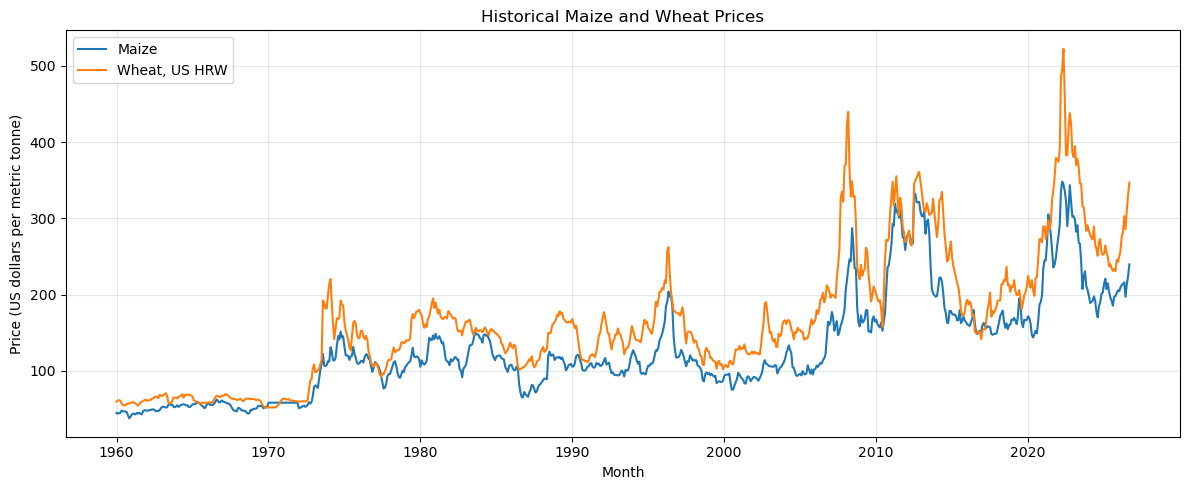

In [14]:

import matplotlib.pyplot as plt

food_columns = ["Maize", "Wheat, US HRW"]

plt.figure(figsize=(12, 5))

for col in food_columns:
    plt.plot(df["Month"], df[col], label=col)

plt.title("Historical Maize and Wheat Prices")
plt.xlabel("Month")
plt.ylabel("Price (US dollars per metric tonne)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:

comparison_df = df[
    ["Month", "Crude oil, Brent", "Maize", "Wheat, US HRW"]
].copy()

# Calculate month-on-month percentage changes
for col in ["Crude oil, Brent", "Maize", "Wheat, US HRW"]:
    comparison_df[f"{col} change %"] = (
        comparison_df[col].pct_change() * 100
    )

display(comparison_df.tail(12).round(2))


,Month,"Crude oil, Brent",Maize,"Wheat, US HRW","Crude oil, Brent change %",Maize change %,"Wheat, US HRW change %"
789,2025-10-01,64.7,198.1,230.8,-4.85,0.35,-1.28
790,2025-11-01,63.6,202.0,245.9,-1.70,1.97,6.54
791,2025-12-01,62.7,205.7,242.8,-1.42,1.83,-1.26
792,2026-01-01,66.8,204.5,249.9,6.54,-0.58,2.92
793,2026-02-01,71.1,209.6,257.6,6.44,2.49,3.08
794,2026-03-01,103.7,212.7,276.0,45.85,1.48,7.14
795,2026-04-01,120.4,214.0,282.0,16.10,0.61,2.17
796,2026-05-01,107.5,216.2,303.0,-10.71,1.03,7.45
797,2026-06-01,85.4,197.1,286.0,-20.56,-8.83,-5.61
798,2026-07-01,83.4,213.4,310.0,-2.34,8.27,8.39


In [16]:

# Check the latest 12 observations for missing values
check_columns = [
    "Month",
    "Crude oil, Brent",
    "Maize",
    "Wheat, US HRW"
]

print("Latest 12 observations:")
display(df[check_columns].tail(12))

# Find the largest absolute month-on-month changes
change_columns = [
    "Crude oil, Brent change %",
    "Maize change %",
    "Wheat, US HRW change %"
]

for col in change_columns:
    print(f"\nLargest absolute movements: {col}")
    display(
        comparison_df.loc[
            comparison_df[col].abs().nlargest(5).index,
            ["Month", col]
        ].sort_values("Month")
    )


Latest 12 observations:


,Month,"Crude oil, Brent",Maize,"Wheat, US HRW"
789,2025-10-01,64.7,198.1,230.8
790,2025-11-01,63.6,202.0,245.9
791,2025-12-01,62.7,205.7,242.8
792,2026-01-01,66.8,204.5,249.9
793,2026-02-01,71.1,209.6,257.6
794,2026-03-01,103.7,212.7,276.0
795,2026-04-01,120.4,214.0,282.0
796,2026-05-01,107.5,216.2,303.0
797,2026-06-01,85.4,197.1,286.0
798,2026-07-01,83.4,213.4,310.0



Largest absolute movements: Crude oil, Brent change %


,Month,"Crude oil, Brent change %"
165,1973-10-01,51.851852
168,1974-01-01,217.073171
319,1986-08-01,44.210526
367,1990-08-01,53.977273
794,2026-03-01,45.850914



Largest absolute movements: Maize change %


,Month,Maize change %
318,1986-07-01,-19.806763
341,1988-06-01,34.714446
440,1996-09-01,-21.617251
585,2008-10-01,-21.685201
630,2012-07-01,24.616536



Largest absolute movements: Wheat, US HRW change %


,Month,"Wheat, US HRW change %"
163,1973-08-01,67.975567
572,2007-09-01,25.721987
607,2010-08-01,25.740552
630,2012-07-01,25.162925
746,2022-03-01,24.532650


In [17]:

from pathlib import Path

project_folder = Path(
    r"C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar"
)

processed_folder = project_folder / "data" / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

# Save the cleaned wide-format data
output_file = processed_folder / "commodity_prices_clean.csv"

df.to_csv(output_file, index=False)

print("Export successful:", output_file.exists())
print("Saved to:", output_file)
print("Rows and columns:", df.shape)


Export successful: True
Saved to: C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar\data\processed\commodity_prices_clean.csv
Rows and columns: (801, 72)


In [18]:

# Step 24: Convert wide data into long format

# Keep Month as the date column and reshape commodity columns
commodity_columns = [col for col in df.columns if col != "Month"]

long_df = df.melt(
    id_vars=["Month"],
    value_vars=commodity_columns,
    var_name="commodity_name",
    value_name="price"
)

# Remove rows where a commodity price is unavailable
long_df = long_df.dropna(subset=["Month", "price"]).copy()

# Prepare the columns for MySQL
long_df = long_df.rename(columns={"Month": "observation_date"})
long_df["source"] = "World Bank Commodity Markets"

# Keep only the columns our SQL table needs
long_df = long_df[
    ["observation_date", "commodity_name", "price", "source"]
]

# Inspect the result
print("Long-format dataset shape:", long_df.shape)
display(long_df.head(10))

print("\nNumber of commodities:", long_df["commodity_name"].nunique())
print("Date range:",
      long_df["observation_date"].min(),
      "to",
      long_df["observation_date"].max())


Long-format dataset shape: (50451, 4)


,observation_date,commodity_name,price,source
0,1960-01-01,"Crude oil, average",1.6,World Bank Commodity Markets
1,1960-02-01,"Crude oil, average",1.6,World Bank Commodity Markets
2,1960-03-01,"Crude oil, average",1.6,World Bank Commodity Markets
3,1960-04-01,"Crude oil, average",1.6,World Bank Commodity Markets
4,1960-05-01,"Crude oil, average",1.6,World Bank Commodity Markets
5,1960-06-01,"Crude oil, average",1.6,World Bank Commodity Markets
6,1960-07-01,"Crude oil, average",1.6,World Bank Commodity Markets
7,1960-08-01,"Crude oil, average",1.6,World Bank Commodity Markets
8,1960-09-01,"Crude oil, average",1.6,World Bank Commodity Markets
9,1960-10-01,"Crude oil, average",1.6,World Bank Commodity Markets



Number of commodities: 71
Date range: 1960-01-01 00:00:00 to 2026-09-01 00:00:00


In [19]:

sql_csv = processed_folder / "commodity_prices_long.csv"

long_df.to_csv(sql_csv, index=False)

print("Export successful:", sql_csv.exists())
print("File location:", sql_csv)
print("Rows exported:", len(long_df))


Export successful: True
File location: C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar\data\processed\commodity_prices_long.csv
Rows exported: 50451


In [20]:
# Add an empty unit column for now
long_df["unit"] = None

# Arrange columns to match the MySQL table
long_df = long_df[
    ["observation_date", "commodity_name", "price", "unit", "source"]
]

# Export the final CSV for MySQL
sql_csv = processed_folder / "commodity_prices_long.csv"
long_df.to_csv(sql_csv, index=False)

print("Export successful:", sql_csv.exists())
print("File location:", sql_csv)
print("Rows exported:", len(long_df))
print("\nColumn names:", long_df.columns.tolist())

display(long_df.head())

Export successful: True
File location: C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar\data\processed\commodity_prices_long.csv
Rows exported: 50451

Column names: ['observation_date', 'commodity_name', 'price', 'unit', 'source']


,observation_date,commodity_name,price,unit,source
0,1960-01-01,"Crude oil, average",1.6,None,World Bank Commodity Markets
1,1960-02-01,"Crude oil, average",1.6,None,World Bank Commodity Markets
2,1960-03-01,"Crude oil, average",1.6,None,World Bank Commodity Markets
3,1960-04-01,"Crude oil, average",1.6,None,World Bank Commodity Markets
4,1960-05-01,"Crude oil, average",1.6,None,World Bank Commodity Markets


In [23]:
from pathlib import Path

project_folder = Path(
    r"C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar"
)

processed_folder = project_folder / "data" / "processed"

csv_path = processed_folder / "commodity_monthly_changes.csv"

print("CSV file exists:", csv_path.exists())
print("CSV location:", csv_path)

CSV file exists: True
CSV location: C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar\data\processed\commodity_monthly_changes.csv


In [24]:
import pandas as pd

analysis_df = pd.read_csv(
    csv_path,
    parse_dates=["observation_date"]
)

print("Dataset shape:", analysis_df.shape)

print("\nObservations per commodity:")
display(
    analysis_df.groupby("commodity_name").agg(
        observations=("price", "count"),
        first_date=("observation_date", "min"),
        latest_date=("observation_date", "max")
    ).reset_index()
)

print("\nMissing values:")
display(analysis_df.isna().sum())

Dataset shape: (4722, 5)

Observations per commodity:


,commodity_name,observations,first_date,latest_date
0,"Crude oil, Brent",801,1960-01-01,2026-09-01
1,DAP,717,1967-01-01,2026-09-01
2,Maize,801,1960-01-01,2026-09-01
3,"Rice, Thai 5%",801,1960-01-01,2026-09-01
4,Urea,801,1960-01-01,2026-09-01
5,"Wheat, US HRW",801,1960-01-01,2026-09-01



Missing values:


observation_date      0
commodity_name        0
price                 0
previous_price        6
monthly_change_pct    6
dtype: int64

In [25]:
print("Observations per commodity:")
display(
    analysis_df.groupby("commodity_name").agg(
        observations=("price", "count"),
        first_date=("observation_date", "min"),
        latest_date=("observation_date", "max")
    ).reset_index()
)

print("\nMissing values:")
display(analysis_df.isna().sum())

Observations per commodity:


,commodity_name,observations,first_date,latest_date
0,"Crude oil, Brent",801,1960-01-01,2026-09-01
1,DAP,717,1967-01-01,2026-09-01
2,Maize,801,1960-01-01,2026-09-01
3,"Rice, Thai 5%",801,1960-01-01,2026-09-01
4,Urea,801,1960-01-01,2026-09-01
5,"Wheat, US HRW",801,1960-01-01,2026-09-01



Missing values:


observation_date      0
commodity_name        0
price                 0
previous_price        6
monthly_change_pct    6
dtype: int64

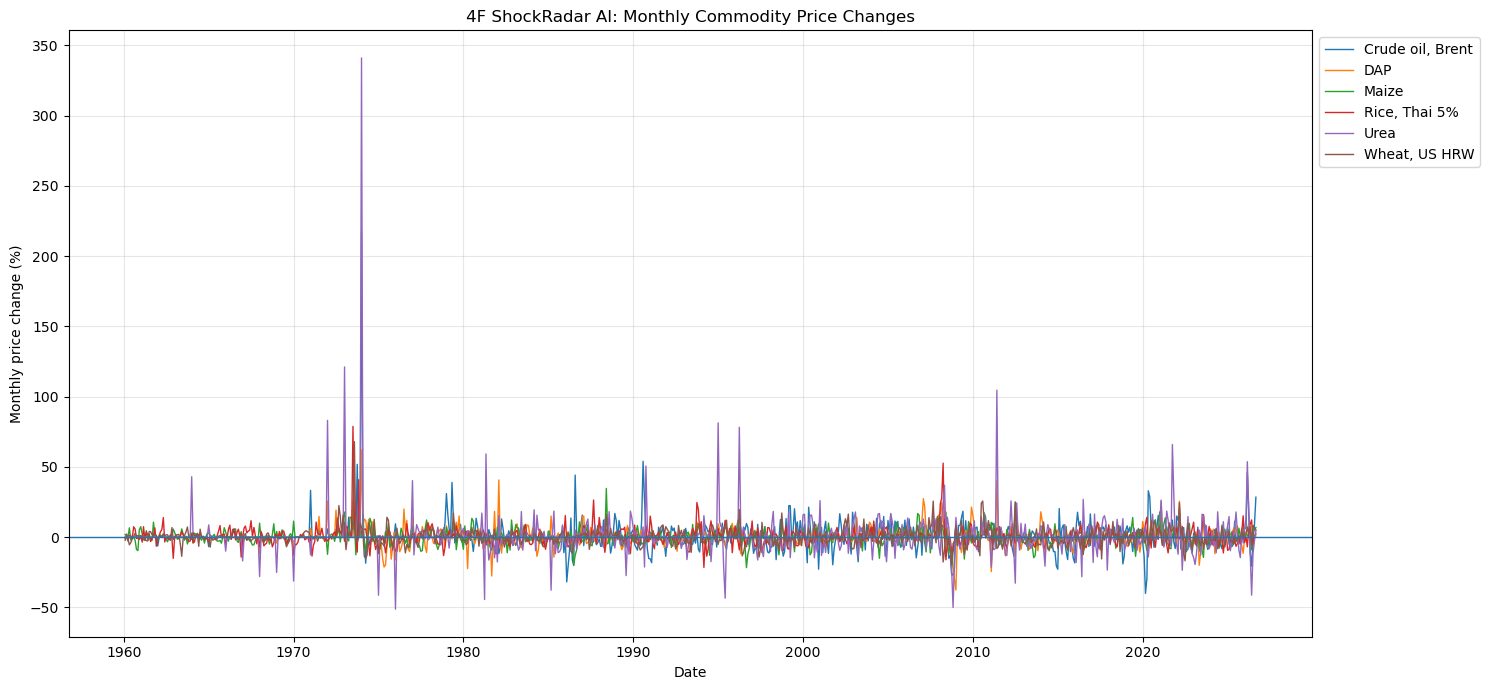

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

# Ensure dates and numeric values are correctly formatted
analysis_df["observation_date"] = pd.to_datetime(
    analysis_df["observation_date"]
)
analysis_df["price"] = pd.to_numeric(
    analysis_df["price"], errors="coerce"
)

# Keep the six indicators in chronological order
analysis_df = analysis_df.sort_values(
    ["commodity_name", "observation_date"]
).copy()

# Calculate monthly percentage change for each commodity
analysis_df["monthly_change_pct"] = (
    analysis_df.groupby("commodity_name")["price"]
    .pct_change() * 100
)

# Plot monthly percentage changes
plt.figure(figsize=(15, 7))

for commodity in sorted(analysis_df["commodity_name"].unique()):
    commodity_data = analysis_df[
        analysis_df["commodity_name"] == commodity
    ]

    plt.plot(
        commodity_data["observation_date"],
        commodity_data["monthly_change_pct"],
        label=commodity,
        linewidth=1
    )

plt.axhline(0, linewidth=1)
plt.title("4F ShockRadar AI: Monthly Commodity Price Changes")
plt.xlabel("Date")
plt.ylabel("Monthly price change (%)")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [27]:

# Calculate previous month's price for each commodity
analysis_df["previous_price"] = (
    analysis_df.groupby("commodity_name")["price"].shift(1)
)

# Find the 15 largest movements by absolute percentage change
extreme_changes = (
    analysis_df.dropna(subset=["monthly_change_pct"])
    .assign(
        absolute_change=lambda x: x["monthly_change_pct"].abs()
    )
    .sort_values("absolute_change", ascending=False)
    [[
        "observation_date",
        "commodity_name",
        "previous_price",
        "price",
        "monthly_change_pct"
    ]]
    .head(15)
)

display(extreme_changes)


,observation_date,commodity_name,previous_price,price,monthly_change_pct
928,1974-01-01,Urea,64.8,285.8,341.049383
924,1974-01-01,"Crude oil, Brent",4.1,13.0,217.073171
856,1973-01-01,Urea,29.3,64.8,121.160410
3622,2011-06-01,Urea,234.0,478.8,104.615385
784,1972-01-01,Urea,16.0,29.3,83.125000
2440,1995-01-01,Urea,88.0,159.6,81.363636
891,1973-07-01,"Rice, Thai 5%",185.9,332.5,78.859602
2530,1996-04-01,Urea,90.0,160.4,78.222222
899,1973-08-01,"Wheat, US HRW",114.6,192.5,67.975567
4366,2021-10-01,Urea,418.8,695.0,65.950334


In [28]:

# Focus on the six indicators and their largest movements
shock_check = analysis_df[
    analysis_df["monthly_change_pct"] >= 30
].copy()

shock_summary = (
    shock_check.groupby("commodity_name")
    .agg(
        shock_months=("monthly_change_pct", "count"),
        largest_increase=("monthly_change_pct", "max"),
        average_increase=("monthly_change_pct", "mean"),
        first_shock=("observation_date", "min"),
        latest_shock=("observation_date", "max")
    )
    .reset_index()
    .sort_values("shock_months", ascending=False)
)

display(shock_summary)


,commodity_name,shock_months,largest_increase,average_increase,first_shock,latest_shock
4,Urea,13,341.049383,89.188034,1964-01-01,2026-03-01
0,"Crude oil, Brent",9,217.073171,61.040201,1971-01-01,2026-03-01
1,DAP,3,62.264151,47.822769,1974-01-01,2011-06-01
3,"Rice, Thai 5%",3,78.859602,57.492367,1973-07-01,2008-04-01
2,Maize,1,34.714446,34.714446,1988-06-01,1988-06-01
5,"Wheat, US HRW",1,67.975567,67.975567,1973-08-01,1973-08-01


In [29]:

import numpy as np

def classify_price_movement(change):
    if pd.isna(change):
        return "No previous observation"
    elif change < 0:
        return "Price decrease"
    elif change < 10:
        return "Normal"
    elif change < 30:
        return "Moderate"
    else:
        return "High"

analysis_df["shock_category"] = (
    analysis_df["monthly_change_pct"]
    .apply(classify_price_movement)
)

category_summary = (
    analysis_df.groupby(
        ["commodity_name", "shock_category"]
    )
    .size()
    .unstack(fill_value=0)
)

display(category_summary)


shock_category,High,Moderate,No previous observation,Normal,Price decrease
commodity_name,,,,,
"Crude oil, Brent",9,57,1,458,276
DAP,3,43,1,367,303
Maize,1,36,1,397,366
"Rice, Thai 5%",3,26,1,394,377
Urea,13,65,1,484,238
"Wheat, US HRW",1,32,1,393,374


In [30]:

# Sort observations chronologically within each commodity
analysis_df = analysis_df.sort_values(
    ["commodity_name", "observation_date"]
).copy()

# Calculate next month's percentage change
analysis_df["next_month_change_pct"] = (
    analysis_df.groupby("commodity_name")["monthly_change_pct"]
    .shift(-1)
)

# Create target: 1 = next month's increase is at least 10%
analysis_df["target_next_month_shock"] = (
    analysis_df["next_month_change_pct"] >= 10
).astype("Int64")

# Remove rows where the next month's movement is unknown
ml_df = analysis_df.dropna(
    subset=["next_month_change_pct"]
).copy()

# Check the prediction target
print("ML dataset shape:", ml_df.shape)

print("\nTarget distribution:")
display(
    ml_df["target_next_month_shock"]
    .value_counts()
    .rename(index={0: "No high increase", 1: "High increase"})
)

print("\nTarget percentage:")
display(
    ml_df["target_next_month_shock"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


ML dataset shape: (4716, 8)

Target distribution:


target_next_month_shock
No high increase    4427
High increase        289
Name: count, dtype: Int64


Target percentage:


target_next_month_shock
0    93.87
1     6.13
Name: proportion, dtype: Float64

In [31]:

# Work on a copy
ml_features = ml_df.copy()

# Previous month's percentage change
ml_features["previous_month_change_pct"] = (
    ml_features.groupby("commodity_name")["monthly_change_pct"]
    .shift(1)
)

# Average change over the current and previous two months
ml_features["three_month_avg_change_pct"] = (
    ml_features.groupby("commodity_name")["monthly_change_pct"]
    .transform(lambda s: s.rolling(window=3, min_periods=3).mean())
)

# Keep only rows with complete predictor information
ml_features = ml_features.dropna(
    subset=[
        "monthly_change_pct",
        "previous_month_change_pct",
        "three_month_avg_change_pct",
        "target_next_month_shock"
    ]
).copy()

print("Feature dataset shape:", ml_features.shape)

print("\nFeatures:")
print([
    "commodity_name",
    "monthly_change_pct",
    "previous_month_change_pct",
    "three_month_avg_change_pct"
])

print("\nTarget distribution:")
display(ml_features["target_next_month_shock"].value_counts())



Feature dataset shape: (4698, 10)

Features:
['commodity_name', 'monthly_change_pct', 'previous_month_change_pct', 'three_month_avg_change_pct']

Target distribution:


target_next_month_shock
0    4409
1     289
Name: count, dtype: Int64

In [32]:

# Sort by observation date
ml_features = ml_features.sort_values(
    "observation_date"
).copy()

# Use the first 80% of unique months for training
unique_dates = sorted(
    ml_features["observation_date"].unique()
)

split_index = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[split_index]

train_df = ml_features[
    ml_features["observation_date"] < cutoff_date
].copy()

test_df = ml_features[
    ml_features["observation_date"] >= cutoff_date
].copy()

print("Training period:")
print(train_df["observation_date"].min(),
      "to", train_df["observation_date"].max())

print("\nTesting period:")
print(test_df["observation_date"].min(),
      "to", test_df["observation_date"].max())

print("\nTraining rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining positive rate:")
print(
    round(train_df["target_next_month_shock"].mean() * 100, 2),
    "%"
)

print("\nTesting positive rate:")
print(
    round(test_df["target_next_month_shock"].mean() * 100, 2),
    "%"
)


Training period:
1960-04-01 00:00:00 to 2013-04-01 00:00:00

Testing period:
2013-05-01 00:00:00 to 2026-08-01 00:00:00

Training rows: 3738
Testing rows: 960

Training positive rate:
5.94 %

Testing positive rate:
6.98 %


In [33]:

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Define predictor columns
numeric_features = [
    "monthly_change_pct",
    "previous_month_change_pct",
    "three_month_avg_change_pct"
]

categorical_features = ["commodity_name"]

# Separate predictors and target
X_train = train_df[numeric_features + categorical_features]
X_test = test_df[numeric_features + categorical_features]

y_train = train_df["target_next_month_shock"].astype(int)
y_test = test_df["target_next_month_shock"].astype(int)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),

        ("category", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Model 1: Baseline
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

# Model 2: Logistic Regression
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Evaluation function
def evaluate_model(name, actual, predicted, probabilities=None):
    print(f"\n{name}")
    print("-" * 40)
    print("Accuracy:", round(accuracy_score(actual, predicted), 4))
    print("Precision:", round(
        precision_score(actual, predicted, zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(actual, predicted, zero_division=0), 4
    ))
    print("F1-score:", round(
        f1_score(actual, predicted, zero_division=0), 4
    ))

    if probabilities is not None:
        print("PR-AUC (Average Precision):", round(
            average_precision_score(actual, probabilities), 4
        ))

# Compare both models
evaluate_model(
    "Baseline Model",
    y_test,
    baseline_predictions
)

evaluate_model(
    "Logistic Regression",
    y_test,
    logistic_predictions,
    logistic_probabilities
)

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

print("\nLogistic Regression Classification Report:")
print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))



Baseline Model
----------------------------------------
Accuracy: 0.9302
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Logistic Regression
----------------------------------------
Accuracy: 0.6344
Precision: 0.112
Recall: 0.6119
F1-score: 0.1894
PR-AUC (Average Precision): 0.2175

Logistic Regression Confusion Matrix:
[[568 325]
 [ 26  41]]

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.64      0.76       893
           1       0.11      0.61      0.19        67

    accuracy                           0.63       960
   macro avg       0.53      0.62      0.48       960
weighted avg       0.90      0.63      0.72       960



In [34]:

from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score, f1_score

# Split the original training period into model-training
# and validation periods
train_dates = sorted(train_df["observation_date"].unique())

validation_index = int(len(train_dates) * 0.8)
validation_start = train_dates[validation_index]

# Leave a one-month gap to respect the next-month prediction target
training_cutoff = validation_start - pd.DateOffset(months=1)

subtrain_df = train_df[
    train_df["observation_date"] < training_cutoff
].copy()

validation_df = train_df[
    train_df["observation_date"] >= validation_start
].copy()

X_subtrain = subtrain_df[
    numeric_features + categorical_features
]
y_subtrain = subtrain_df["target_next_month_shock"].astype(int)

X_validation = validation_df[
    numeric_features + categorical_features
]
y_validation = validation_df["target_next_month_shock"].astype(int)

# Train a fresh copy of Logistic Regression
validation_model = clone(logistic_model)
validation_model.fit(X_subtrain, y_subtrain)

validation_probabilities = validation_model.predict_proba(
    X_validation
)[:, 1]

# Compare different warning thresholds
threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "predicted_shocks": int(predictions.sum())
    })

threshold_table = pd.DataFrame(threshold_results)

display(threshold_table.round(3))

print("Validation period:")
print(
    validation_df["observation_date"].min(),
    "to",
    validation_df["observation_date"].max()
)
print("Validation rows:", len(validation_df))
print("Actual high increases:", int(y_validation.sum()))


,threshold,precision,recall,f1_score,predicted_shocks
0,0.1,0.108,1.000,0.195,768
1,0.2,0.108,1.000,0.195,768
2,0.3,0.109,1.000,0.196,764
3,0.4,0.117,0.892,0.207,632
4,0.5,0.183,0.711,0.291,322


Validation period:
2002-09-01 00:00:00 to 2013-04-01 00:00:00
Validation rows: 768
Actual high increases: 83


In [36]:

from sklearn.base import clone
from sklearn.metrics import confusion_matrix

# Retrain using the complete training dataset
final_logistic_model = clone(logistic_model)

final_logistic_model.fit(X_train, y_train)

# Predict probabilities on untouched test data
test_probabilities = final_logistic_model.predict_proba(
    X_test
)[:, 1]

# Apply the selected validation threshold
selected_threshold = 0.50

final_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

# Evaluate final performance
print("FINAL LOGISTIC REGRESSION RESULTS")
print("----------------------------------")

print("Threshold:", selected_threshold)

print("Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test, final_predictions), 4))

print("Recall:",
      round(recall_score(y_test, final_predictions), 4))

print("F1-score:",
      round(f1_score(y_test, final_predictions), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, test_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))


FINAL LOGISTIC REGRESSION RESULTS
----------------------------------
Threshold: 0.5
Accuracy: 0.6344
Precision: 0.112
Recall: 0.6119
F1-score: 0.1894
PR-AUC: 0.2175

Confusion Matrix:
[[568 325]
 [ 26  41]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.64      0.76       893
           1       0.11      0.61      0.19        67

    accuracy                           0.63       960
   macro avg       0.53      0.62      0.48       960
weighted avg       0.90      0.63      0.72       960



In [37]:

# Identify the first test month
test_start = test_df["observation_date"].min()

# Remove training rows whose target falls in the test period
corrected_train_df = train_df[
    train_df["observation_date"] < (
        test_start - pd.DateOffset(months=1)
    )
].copy()

# Rebuild training predictors and target
X_train = corrected_train_df[
    numeric_features + categorical_features
]

y_train = corrected_train_df[
    "target_next_month_shock"
].astype(int)

# Test data remains unchanged
X_test = test_df[
    numeric_features + categorical_features
]

y_test = test_df[
    "target_next_month_shock"
].astype(int)

print("Corrected training rows:", len(X_train))
print("Test rows:", len(X_test))

print("Last training observation:",
      corrected_train_df["observation_date"].max())

print("First test observation:",
      test_df["observation_date"].min())


Corrected training rows: 3732
Test rows: 960
Last training observation: 2013-03-01 00:00:00
First test observation: 2013-05-01 00:00:00


In [38]:

final_logistic_model = clone(logistic_model)

final_logistic_model.fit(X_train, y_train)

test_probabilities = final_logistic_model.predict_proba(
    X_test
)[:, 1]

final_predictions = (
    test_probabilities >= 0.50
).astype(int)

evaluate_model(
    "Corrected Logistic Regression",
    y_test,
    final_predictions,
    test_probabilities
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))



Corrected Logistic Regression
----------------------------------------
Accuracy: 0.6333
Precision: 0.1117
Recall: 0.6119
F1-score: 0.1889
PR-AUC (Average Precision): 0.2173

Confusion Matrix:
[[567 326]
 [ 26  41]]


In [39]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using corrected training data
random_forest_model.fit(X_train, y_train)

# Predict on the same test period
rf_predictions = random_forest_model.predict(X_test)

rf_probabilities = random_forest_model.predict_proba(
    X_test
)[:, 1]

# Evaluate Random Forest
print("RANDOM FOREST RESULTS")
print("----------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 4))

print("Precision:",
      round(precision_score(y_test, rf_predictions, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, rf_predictions, zero_division=0), 4))

print("F1-score:",
      round(f1_score(y_test, rf_predictions, zero_division=0), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, rf_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))


RANDOM FOREST RESULTS
----------------------------------
Accuracy: 0.8583
Precision: 0.165
Recall: 0.2537
F1-score: 0.2
PR-AUC: 0.1388

Confusion Matrix:
[[807  86]
 [ 50  17]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92       893
           1       0.17      0.25      0.20        67

    accuracy                           0.86       960
   macro avg       0.55      0.58      0.56       960
weighted avg       0.89      0.86      0.87       960



In [40]:

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(
            y_test,
            final_logistic_model.predict(X_test)
        ),
        "Precision": precision_score(
            y_test,
            final_logistic_model.predict(X_test),
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            final_logistic_model.predict(X_test),
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test,
            final_logistic_model.predict(X_test),
            zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test,
            final_logistic_model.predict_proba(X_test)[:, 1]
        )
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_predictions),
        "Precision": precision_score(
            y_test, rf_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, rf_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, rf_predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test, rf_probabilities
        )
    }
])

display(model_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.6333,0.1117,0.6119,0.1889,0.2173
1,Random Forest,0.8583,0.1650,0.2537,0.2000,0.1388


In [41]:

from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Train Random Forest using the training subset
rf_validation_model = clone(random_forest_model)

rf_validation_model.fit(X_subtrain, y_subtrain)

# Predict probabilities on validation data
rf_validation_probabilities = (
    rf_validation_model.predict_proba(X_validation)[:, 1]
)

# Evaluate different thresholds
results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    predictions = (
        rf_validation_probabilities >= threshold
    ).astype(int)

    results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_validation, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_validation, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_validation, predictions, zero_division=0
        ),
        "predicted_shocks": int(predictions.sum())
    })

rf_threshold_table = pd.DataFrame(results)

print("RANDOM FOREST VALIDATION RESULTS")
display(rf_threshold_table.round(3))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_validation,
            rf_validation_probabilities
        ), 4
    )
)


RANDOM FOREST VALIDATION RESULTS


,threshold,precision,recall,f1_score,predicted_shocks
0,0.1,0.110,1.000,0.198,754
1,0.2,0.121,0.892,0.213,611
2,0.3,0.146,0.602,0.235,342
3,0.4,0.194,0.398,0.261,170
4,0.5,0.217,0.217,0.217,83


Validation PR-AUC: 0.1687


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Get predicted probabilities for the test set
rf_test_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
rf_test_predictions = (
    rf_test_probabilities >= 0.40
).astype(int)

print("RANDOM FOREST TEST RESULTS — THRESHOLD 0.40")
print("Accuracy:", round(accuracy_score(y_test, rf_test_predictions), 4))
print("Precision:", round(precision_score(y_test, rf_test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_test_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, rf_test_predictions, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_test, rf_test_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_test_predictions, zero_division=0))

RANDOM FOREST TEST RESULTS — THRESHOLD 0.40
Accuracy: 0.7802
Precision: 0.1505
Recall: 0.4627
F1-score: 0.2271
PR-AUC: 0.1388

Confusion Matrix:
[[718 175]
 [ 36  31]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.80      0.87       893
           1       0.15      0.46      0.23        67

    accuracy                           0.78       960
   macro avg       0.55      0.63      0.55       960
weighted avg       0.90      0.78      0.83       960



In [43]:
# Random Forest feature importance
rf_preprocessor = random_forest_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

rf_importance = (
    random_forest_model.named_steps["classifier"]
    .feature_importances_
)

rf_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_importance
}).sort_values("importance", ascending=False)

display(rf_importance_df)

,feature,importance
2,numeric__three_month_avg_change_pct,0.336063
0,numeric__monthly_change_pct,0.310171
1,numeric__previous_month_change_pct,0.247644
6,"category__commodity_name_Rice, Thai 5%",0.023751
7,category__commodity_name_Urea,0.021449
3,"category__commodity_name_Crude oil, Brent",0.018910
8,"category__commodity_name_Wheat, US HRW",0.015249
5,category__commodity_name_Maize,0.015198
4,category__commodity_name_DAP,0.011564


In [44]:
import joblib
from pathlib import Path

project_folder = Path(
    r"C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar"
)

models_folder = project_folder / "models"
models_folder.mkdir(parents=True, exist_ok=True)

# Save both trained models
joblib.dump(
    logistic_model,
    models_folder / "logistic_shock_model.pkl"
)

joblib.dump(
    random_forest_model,
    models_folder / "random_forest_shock_model.pkl"
)

# Save selected prediction thresholds
joblib.dump(
    {"logistic": 0.50, "random_forest": 0.40},
    models_folder / "model_thresholds.pkl"
)

print("Models saved successfully!")
print("Saved location:", models_folder)

Models saved successfully!
Saved location: C:\Users\DELL\OneDrive\Desktop\projects\4F Shock radar\models
